# Exercise 4 — Which H-alpha filter?

*Covers notebooks 03. Difficulty: ★★★☆☆*

H II regions and star-forming knots are emission lines on a continuum. The WCC has three H-alpha filters of different width: which gives the best line SNR, and how does the answer depend on the continuum?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

### 4.0 — A broken cell

The cell below is broken on purpose. Run it, paste the traceback into Jupyter AI (or read it
yourself), fix it, and keep the fixed version: it builds the simulations the rest of the exercise
uses.

In [2]:
filters = ["zwo:halpha2", "zwo:halpha6", "zwo:halpha20", "zwo:r"]
line = [{"wave": 6563.0, "flux": 1e-15, "fwhm": 4}]              # erg/s/cm^2, Angstrom
# fixed: emission sources carry absolute line fluxes, so mag must be None (mag=18 raised a ValueError)
sims = {f: Simulation.from_sensorfilter(f, get_scene("emission", mag=None, lines=line)) for f in filters}

### 4.1 — The filters

Tabulate for each filter the FWHM of the installed throughput curve (sample `sim.sensor.bandpass(w)`
on a fine grid) and the throughput at 6563 Å, and plot the four curves between 6200 and 6900 Å
with the line drawn on top.

filter         FWHM [A]  T(6563)
zwo:halpha2        20.3    0.357
zwo:halpha6        60.9    0.357
zwo:halpha20      202.6    0.357
zwo:r            1338.6    0.365


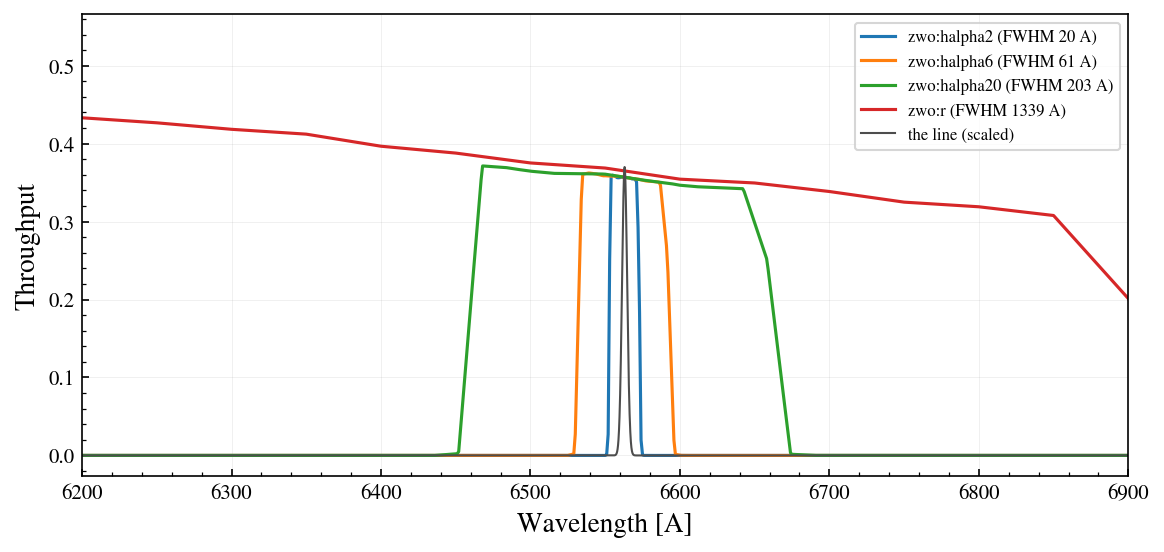

In [3]:
w = np.arange(5000, 7500, 0.05)
fwhm = {}
print(f"{'filter':13s} {'FWHM [A]':>9s} {'T(6563)':>8s}")
for f, s in sims.items():
    T = s.sensor.bandpass(w).value; half = w[T >= T.max() / 2]
    fwhm[f] = half.max() - half.min()
    print(f"{f:13s} {fwhm[f]:9.1f} {s.sensor.bandpass(6563.0).value:8.3f}")
fig, ax = plt.subplots(figsize=(9, 4))
for f, s in sims.items():
    wcc_etc.plot_bandpass_mpl(s.sensor, ax=ax, label=f"{f} (FWHM {fwhm[f]:.0f} A)")
ax.plot(w, 0.37 * np.exp(-0.5 * ((w - 6563) / (4 / 2.355)) ** 2), color="0.3", lw=1, label="the line (scaled)")
ax.set(xlim=(6200, 6900)); ax.legend(fontsize=8)
plt.show()

### 4.2 — A pure line

The line SNR in 300 s in each filter, no continuum. Why are the three H-alpha filters so close?

In [4]:
for f, s in sims.items():
    print(f"{f:13s}: SNR = {s.get_image_snr(300, warn=False)['snr']:5.1f}")
# Same line photons in all three; only the (small) zodiacal background grows with filter width.

[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6551-6555 A, 6571-6575 A; the edge flux value is extrapolated there.
  warnings.warn(


zwo:halpha2  : SNR =  42.6
zwo:halpha6  : SNR =  42.5


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6526-6555 A, 6571-6600 A; the edge flux value is extrapolated there.
  warnings.warn(
/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6439-6555 A, 6571-6686 A; the edge flux value is extrapolated there.
  warnings.warn(


zwo:halpha20 : SNR =  42.4
zwo:r        : SNR =  41.6


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 5450-6555 A, 6571-7000 A; the edge flux value is extrapolated there.
  warnings.warn(


> ✏️ **Before you run the next cell:** with a V = 15 continuum under the line, which filter wins, and is the 200 Å filter still usable? Write your guess down (or put it in the room poll), then run.

### 4.3 — A line on a continuum

Now the line sits on a G5V-like continuum of V = 13 to 22 (Vega), passed as a point-source host:
`host="G5V", host_prop={"mag": V, "bandpass": "johnson_v", "magsys": "vegamag"}`. Plot the line SNR in
300 s against continuum magnitude for the four filters, omitting saturated points (split the r
exposure into 30 reads). Where does each filter win?

/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6551-6555 A, 6571-6575 A; the edge flux value is extrapolated there.
  warnings.warn(


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6526-6555 A, 6571-6600 A; the edge flux value is extrapolated there.
  warnings.warn(


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6439-6555 A, 6571-6686 A; the edge flux value is extrapolated there.
  warnings.warn(


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 5450-6555 A, 6571-7000 A; the edge flux value is extrapolated there.
  warnings.warn(


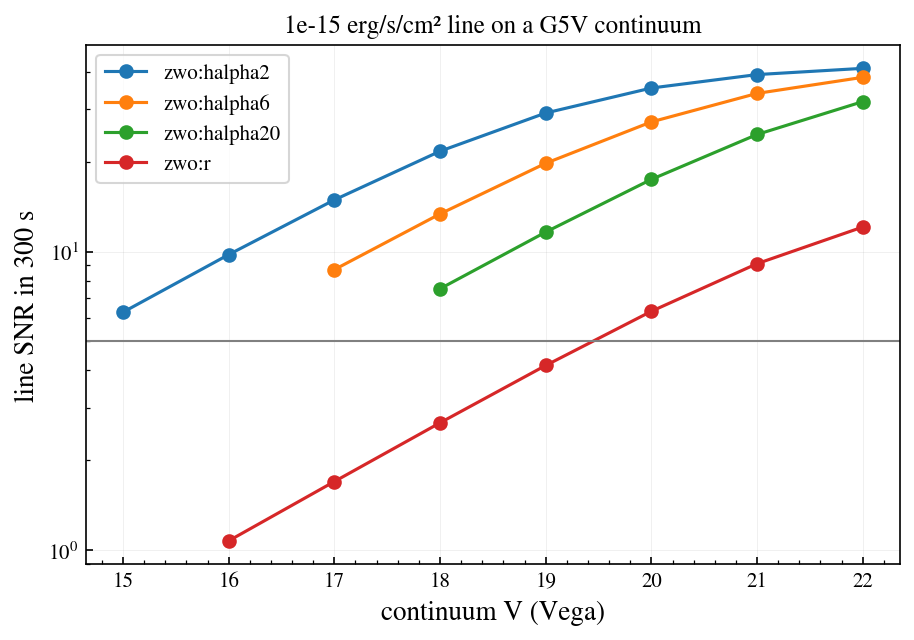

In [5]:
host_mags = np.arange(13, 22.5, 1.0)
fig, ax = plt.subplots(figsize=(7, 4.5))
for f in filters:
    s = Simulation.from_sensorfilter(f, get_scene("emission", mag=None, lines=line, host="G5V",
                                                   host_prop={"mag": 17, "bandpass": "johnson_v", "magsys": "vegamag"}))
    snr = []
    for m in host_mags:
        s.update(host__mag=float(m))
        r = s.get_image_snr(300, n_reads=30 if f == "zwo:r" else 1, warn=False)
        snr.append(np.nan if r["saturated"] else r["snr"])
    ax.semilogy(host_mags, snr, "o-", label=f)
ax.axhline(5, color="0.5", lw=1)
ax.set(xlabel="continuum V (Vega)", ylabel="line SNR in 300 s", title="1e-15 erg/s/cm² line on a G5V continuum"); ax.legend()
plt.show()

### 4.4 — Limiting line flux

For a V = 18 continuum, find the 5 sigma limiting line flux in 300 s in each filter (sweep the line
flux with `s.update(source__lines=[...])` over $10^{-17}$ to $10^{-14}$ erg/s/cm²).

In [6]:
fluxes = np.logspace(-17, -14, 13)
for f in filters:
    s = Simulation.from_sensorfilter(f, get_scene("emission", mag=None, lines=line, host="G5V",
                                                   host_prop={"mag": 18, "bandpass": "johnson_v", "magsys": "vegamag"}))
    snr = []
    for fl in fluxes:
        s.update(source__lines=[{"wave": 6563.0, "flux": float(fl), "fwhm": 4}])
        r = s.get_image_snr(300, n_reads=30 if f == "zwo:r" else 1, warn=False)
        snr.append(np.nan if r["saturated"] else r["snr"])
    snr = np.array(snr)
    print(f"{f:13s}: 5 sigma line flux = {10 ** np.interp(np.log10(5), np.log10(snr), np.log10(fluxes)):.1e} erg/s/cm²")

/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6551-6555 A, 6571-6575 A; the edge flux value is extrapolated there.
  warnings.warn(


zwo:halpha2  : 5 sigma line flux = 2.1e-16 erg/s/cm²


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6526-6555 A, 6571-6600 A; the edge flux value is extrapolated there.
  warnings.warn(


zwo:halpha6  : 5 sigma line flux = 3.6e-16 erg/s/cm²


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 6439-6555 A, 6571-6686 A; the edge flux value is extrapolated there.
  warnings.warn(


zwo:halpha20 : 5 sigma line flux = 6.6e-16 erg/s/cm²


/Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/wcc-etc4/wcc-etc/src/wcc_etc/scene.py:290: UserWarning: spectrum (6555-6571 A) does not cover the bandpass over 5450-6555 A, 6571-7000 A; the edge flux value is extrapolated there.
  warnings.warn(


zwo:r        : 5 sigma line flux = 1.9e-15 erg/s/cm²


> 🤖 **Ask Jupyter AI:** *My H II region has a radial velocity of +900 km/s. Shift the line wavelength accordingly, recompute 4.2, and tell me which filters still transmit it.*
>
> The fix is one number; the agent should also explain the FWHM-to-km/s conversion.

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/wcc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*